In [ ]:

import os
import pandas as pd
import numpy as np

file_path = "/NF-CSE-CIC-IDS2018.parquet"

if not os.path.exists(file_path):
    file_path = "/content/NF-CSE-CIC-IDS2018.parquet"

df = pd.read_parquet(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset shape: (5918803, 12)
Columns: ['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']


In [ ]:

from sklearn.model_selection import train_test_split

# Clean the data
df = df.drop_duplicates().copy()
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(subset=["Label", "Attack"], inplace=True)

# Take a reproducible 500,000-row stratified sample
sample_size = min(500_000, len(df))

df_sample, _ = train_test_split(
    df,
    train_size=sample_size,
    stratify=df["Label"],
    random_state=42
)

df_sample = df_sample.reset_index(drop=True)

# Binary and multi-class labels
y_binary = df_sample["Label"].astype(int)
y_multi = df_sample["Attack"].astype(str)

# Exclude labels and source/destination ports
X = df_sample.drop(
    columns=["Label", "Attack", "L4_SRC_PORT", "L4_DST_PORT"],
    errors="ignore"
)

X = X.select_dtypes(include=[np.number]).copy()
X.replace([np.inf, -np.inf], np.nan, inplace=True)
X = X.fillna(X.median())

# Binary train/test split
X_train, X_test, y_binary_train, y_binary_test = train_test_split(
    X, y_binary,
    test_size=0.20,
    stratify=y_binary,
    random_state=42
)

# Multi-class train/test split
X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X, y_multi,
    test_size=0.20,
    stratify=y_multi,
    random_state=42
)

print("Preprocessing complete!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_binary_train:", y_binary_train.shape)
print("y_multi_train:", y_multi_train.shape)


Preprocessing complete!
X_train: (400000, 8)
X_test: (100000, 8)
y_binary_train: (400000,)
y_multi_train: (400000,)


XGBoost training time: 5.04 seconds


,Model,Task,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC,Training_time_s,Inference_time_per_sample_ms
0,XGBoost,Binary,0.9818,0.9247,0.925,0.9248,0.9818,0.9638,5.0378,0.0039



Classification report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99     93512
      Attack       0.86      0.86      0.86      6488

    accuracy                           0.98    100000
   macro avg       0.92      0.92      0.92    100000
weighted avg       0.98      0.98      0.98    100000



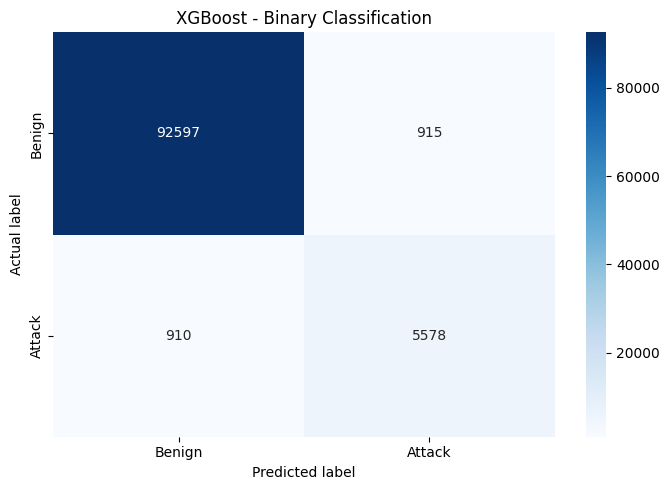

In [ ]:

%pip install -q xgboost

import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

# Balance the benign and attack classes using sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_binary_train
)

# Configure XGBoost
xgb_binary_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

# Train and measure training time
start_time = time.time()

xgb_binary_model.fit(
    X_train,
    y_binary_train,
    sample_weight=sample_weights
)

xgb_binary_train_time = time.time() - start_time
print(f"XGBoost training time: {xgb_binary_train_time:.2f} seconds")

# Predict and measure inference time
start_time = time.time()

xgb_binary_pred = xgb_binary_model.predict(X_test)
xgb_binary_prob = xgb_binary_model.predict_proba(X_test)[:, 1]

xgb_binary_inference_ms = (
    (time.time() - start_time) / len(X_test)
) * 1000

# Evaluate
xgb_binary_results = {
    "Model": "XGBoost",
    "Task": "Binary",
    "Accuracy": accuracy_score(y_binary_test, xgb_binary_pred),
    "Precision_macro": precision_score(
        y_binary_test, xgb_binary_pred,
        average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        y_binary_test, xgb_binary_pred,
        average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        y_binary_test, xgb_binary_pred,
        average="macro", zero_division=0
    ),
    "F1_weighted": f1_score(
        y_binary_test, xgb_binary_pred,
        average="weighted", zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_binary_test, xgb_binary_prob),
    "Training_time_s": xgb_binary_train_time,
    "Inference_time_per_sample_ms": xgb_binary_inference_ms
}

display(pd.DataFrame([xgb_binary_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_binary_test,
    xgb_binary_pred,
    labels=[0, 1],
    target_names=["Benign", "Attack"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_binary_test, xgb_binary_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("XGBoost - Binary Classification")
plt.tight_layout()
plt.savefig("xgb_binary_confusion_matrix.png", dpi=300)
plt.show()


Number of classes: 15
Attack classes: ['Benign', 'Bot', 'Brute Force -Web', 'Brute Force -XSS', 'DDOS attack-HOIC', 'DDOS attack-LOIC-UDP', 'DDoS attacks-LOIC-HTTP', 'DoS attacks-GoldenEye', 'DoS attacks-Hulk', 'DoS attacks-SlowHTTPTest', 'DoS attacks-Slowloris', 'FTP-BruteForce', 'Infilteration', 'SQL Injection', 'SSH-Bruteforce']

XGBoost multi-class training time: 56.20 seconds


,Model,Task,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,Training_time_s,Inference_time_per_sample_ms
0,XGBoost,Multi-class,0.5985,0.584,0.7235,0.6089,0.7303,56.1976,0.0668



Classification report:
                          precision    recall  f1-score   support

                  Benign       1.00      0.58      0.73     93512
                     Bot       1.00      1.00      1.00       244
        Brute Force -Web       0.50      0.25      0.33         4
        Brute Force -XSS       0.33      0.50      0.40         2
        DDOS attack-HOIC       0.43      0.75      0.55         4
    DDOS attack-LOIC-UDP       0.83      1.00      0.91        30
  DDoS attacks-LOIC-HTTP       0.73      0.99      0.84       840
   DoS attacks-GoldenEye       0.72      1.00      0.84       568
        DoS attacks-Hulk       0.87      0.99      0.93      1788
DoS attacks-SlowHTTPTest       0.00      0.00      0.00       235
   DoS attacks-Slowloris       0.83      1.00      0.91       296
          FTP-BruteForce       0.50      1.00      0.67       241
           Infilteration       0.02      0.80      0.04      1014
           SQL Injection       0.00      0.00      

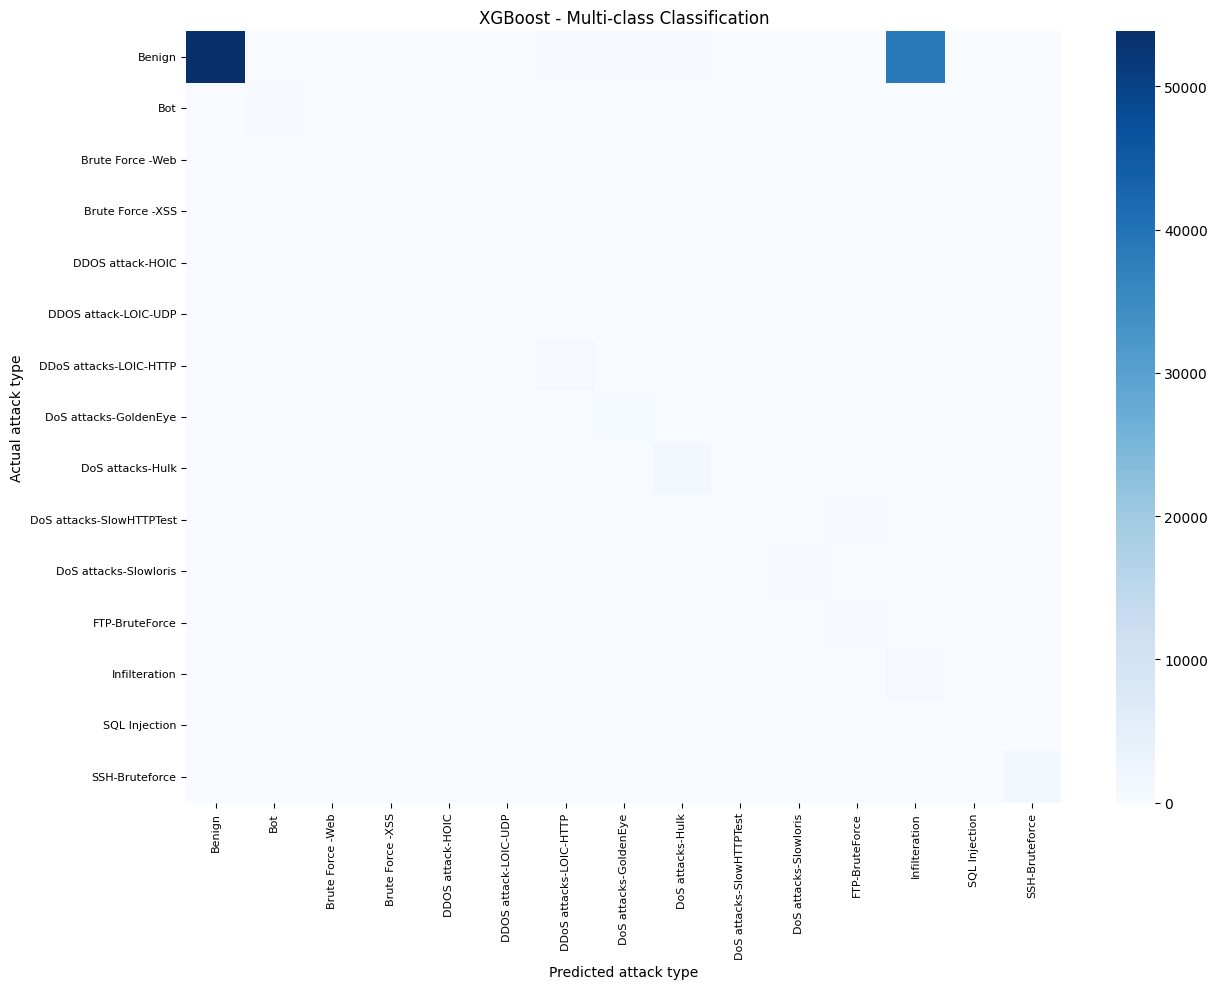

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Encode attack names as integer class IDs
label_encoder = LabelEncoder()

y_multi_train_encoded = label_encoder.fit_transform(y_multi_train)
y_multi_test_encoded = label_encoder.transform(y_multi_test)

print("Number of classes:", len(label_encoder.classes_))
print("Attack classes:", list(label_encoder.classes_))

# Balance the classes in the training set
multi_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_multi_train_encoded
)

# Configure multi-class XGBoost
xgb_multi_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

# Train and measure time
start_time = time.time()

xgb_multi_model.fit(
    X_multi_train,
    y_multi_train_encoded,
    sample_weight=multi_sample_weights
)

xgb_multi_train_time = time.time() - start_time
print(f"\nXGBoost multi-class training time: {xgb_multi_train_time:.2f} seconds")

# Predict and measure inference time
start_time = time.time()

xgb_multi_pred_encoded = xgb_multi_model.predict(X_multi_test)
xgb_multi_prob = xgb_multi_model.predict_proba(X_multi_test)

xgb_multi_inference_ms = (
    (time.time() - start_time) / len(X_multi_test)
) * 1000

# Convert predicted IDs back to attack names
xgb_multi_pred = label_encoder.inverse_transform(
    xgb_multi_pred_encoded.astype(int)
)

# Evaluate multi-class performance
xgb_multi_results = {
    "Model": "XGBoost",
    "Task": "Multi-class",
    "Accuracy": accuracy_score(
        y_multi_test, xgb_multi_pred
    ),
    "Precision_macro": precision_score(
        y_multi_test, xgb_multi_pred,
        average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        y_multi_test, xgb_multi_pred,
        average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        y_multi_test, xgb_multi_pred,
        average="macro", zero_division=0
    ),
    "F1_weighted": f1_score(
        y_multi_test, xgb_multi_pred,
        average="weighted", zero_division=0
    ),
    "Training_time_s": xgb_multi_train_time,
    "Inference_time_per_sample_ms": xgb_multi_inference_ms
}

display(pd.DataFrame([xgb_multi_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_multi_test,
    xgb_multi_pred,
    labels=label_encoder.classes_,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_multi_test,
    xgb_multi_pred,
    labels=label_encoder.classes_
)

plt.figure(figsize=(13, 10))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("XGBoost - Multi-class Classification")
plt.xlabel("Predicted attack type")
plt.ylabel("Actual attack type")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig("xgb_multiclass_confusion_matrix.png", dpi=300)
plt.show()
